In [1]:
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit

In [2]:
import sys
import os
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt


sys.path.append(os.path.join(os.getcwd(), '../../../mouse-2019-stringer/src/'))
from utils_mouse import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [3]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [4]:
file_id = 2

In [5]:
path = os.path.join(read_utils.get_data_path(), '6163622/sessions')

# read
(filename,
 traces,
 continuous_behaviors,
 motion_pcs,
 motion_masks) = read_utils.get_data(path, file_id, with_whisking=True)
timestamps = read_utils.get_timestamps(read_utils.get_filepath(path, file_id))

# clear nan values
# mask = motion_pcs[0].notna().all(axis=1)
mask = continuous_behaviors.notna().all(axis=1)

traces = traces[mask]
motion_pcs[0] = motion_pcs[0][mask]
motion_pcs[1] = motion_pcs[1][mask]
continuous_behaviors = continuous_behaviors[mask]

# naive ID unknown neurons
traces.columns = pd.Index([
	f'{file_id:02d}_{n_id:03d}' if empty or type(label) is not str else label for n_id, (label, empty) in enumerate(zip(traces.columns, traces.columns == ''))
])

# preprocess
classes = pd.DataFrame(
	continuous_behaviors[['running_speed']].values > np.quantile(continuous_behaviors[['running_speed']].values, 0.05),
	columns=['run']
)

In [6]:
(modes_manifold,
 recos_manifold,
 loads_pca_man,
 vars_expl_mans) = train_utils.get_manifolds_pca([traces], scale=False,
												 n_pc=2)

traces_residual = [pd.DataFrame(t.values - t_rec.values, columns=t.columns) for t, t_rec in zip([traces], recos_manifold)][0]

In [7]:
def _acf_1d(x: np.ndarray, max_lag: int | None = None) -> np.ndarray:
    """Normalized autocorrelation (ACF) for non-negative lags."""
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    n = x.size
    if n < 3:
        return np.array([])

    x = x - x.mean()
    var = x.var()
    if var == 0:
        return np.array([])

    if max_lag is None:
        max_lag = n // 4  # simple default
    max_lag = min(max_lag, n - 1)

    acf_full = np.correlate(x, x, mode="full")
    acf = acf_full[n - 1 : n + max_lag]  # lags 0..max_lag
    norm = var * np.arange(n, n - max_lag - 1, -1)  # unbiased normalization
    acf = acf / norm
    return acf


def _exp_decay(lag, A, tau, C):
    return A * np.exp(-lag / tau) + C


def estimate_timescales_from_dataframe(
    df: pd.DataFrame,
    dt: float = 1.0,
    max_lag: int | None = None,
    fit_until_nonpositive: bool = True,
) -> pd.Series:
    """
    For each column in df (one time series per column):
      1) compute ACF
      2) fit single-exponential decay A*exp(-t/tau)+C
      3) return tau for each trace (same index as df.columns)
    """
    taus = {}

    for col in df.columns:
        x = df[col].to_numpy()
        acf = _acf_1d(x, max_lag=max_lag)

        if acf.size < 5:
            taus[col] = np.nan
            continue

        lags = np.arange(acf.size) * dt

        # usually skip lag 0 (always ~1), fit from lag 1 onward
        y = acf[1:]
        t = lags[1:]

        if fit_until_nonpositive:
            pos = np.where(y <= 0)[0]
            if pos.size > 0 and pos[0] >= 3:
                cut = pos[0]
                y = y[:cut]
                t = t[:cut]

        if y.size < 3:
            taus[col] = np.nan
            continue

        # initial guesses
        A0 = max(y[0] - y[-1], 1e-6)
        C0 = max(min(y[-1], 0.5), -0.5)
        tau0 = t[max(1, len(t) // 5)]

        try:
            popt, _ = curve_fit(
                _exp_decay,
                t,
                y,
                p0=[A0, tau0, C0],
                bounds=([0.0, 1e-12, -1.0], [2.0, np.inf, 1.0]),
                maxfev=20000,
            )
            _, tau, _ = popt
            taus[col] = float(tau)
        except Exception:
            taus[col] = np.nan

    return pd.Series(taus, name="tau")


# ---- Example usage ----
# df: columns = traces, rows = time points
# tau_series = estimate_timescales_from_dataframe(df, dt=0.1, max_lag=300)
# print(tau_series.sort_values())

In [8]:
tau_series = estimate_timescales_from_dataframe(traces_residual, dt=0.1, max_lag=300)
# print(tau_series.sort_values())

/tmp/ipykernel_33180/1399514030.py:74: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, _ = curve_fit(


In [9]:
tau_series_eig = estimate_timescales_from_dataframe(motion_pcs[0], dt=0.1, max_lag=300)
# print(tau_series_eig.sort_values())

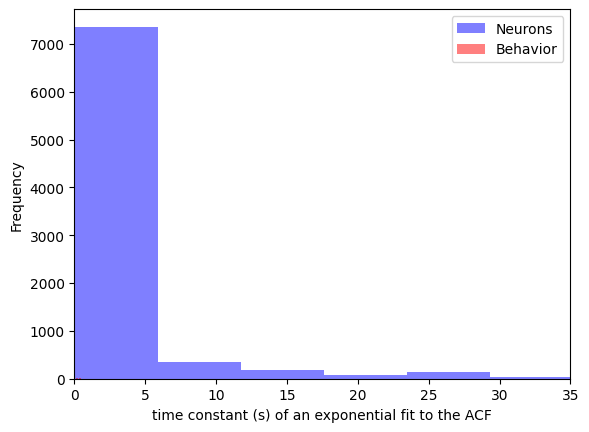

In [10]:
plt.hist(tau_series, bins=9392, label='Neurons', color=(0, 0, 1, 0.5))
plt.hist(tau_series_eig, bins=motion_pcs[0].shape[1], label='Behavior', color=(1, 0, 0, 0.5))
plt.xlim(0, 35)
plt.xlabel('time constant (s) of an exponential fit to the ACF')
plt.ylabel('Frequency')
plt.legend()
# plt.savefig(f'{os.path.expanduser('~')}//Desktop/timescale_mouse.png', dpi=300)